In [ ]:
## Script: 01_MobileNetV2.R
#
# Purpose:
#     Train and evaluate a pretrained MobileNetV2 transfer learning
#     model to classify marine organism images into 12 categories.
#
#
# Input:
#     Marine_Classification/test - 4200 test images
#     Marine_Classification/train - 900 training images
#     Marine_Classification/validation - 900 validation images
# Output:
#     Marine_Classification/mobilenet_results.json - Test accuracy and test loss for the pretrained MobileNetV2 model.
#     Marine_Classification/mobilenetv2_pretrained.keras - Saved pretrained MobileNetV2 model configured for marine organism classification.
#     Marine_Classification/MobileNetV2/Figures/01_observation_availability.png -  Distribution of available image observations across organism categories.
#     Marine_Classification/MobileNetV2/Figures/02_original_image_aspect_ratios.png - Distribution of original image aspect ratios.
#     Marine_Classification/MobileNetV2/Figures/02_original_image_heights.png - Distribution of original image heights.
#     Marine_Classification/MobileNetV2/Figures/02_original_image_resolutions.png -  Distribution of original image resolutions.
#     Marine_Classification/Model_Results/03_misclassified_images.png -  Examples of test images incorrectly classified by MobileNetV2.
#     Marine_Classification/Model_Results/04_f1_score_by_organism.png -  F1 scores for each marine organism category.
#     Marine_Classification/Model_Results/05_confusion_matrix_original.png - Confusion matrix showing the model's original test predictions.
#     Marine_Classification/Model_Results/06_precision_vs_recall.png -  Comparison of precision and recall across organism categories.
#     Marine_Classification/Model_Results/07_precision_by_organism.png - Precision scores for each marine organism category.
#     Marine_Classification/Model_Results/08_confusion_matrix.png -  Confusion matrix showing the model's final test classification results.
# 
#Process:
#     1. Import required Python libraries.
#     2. Connect to Google Drive and define dataset and output paths.
#     3. Load the training, validation, and test image datasets.
#     4. Explore dataset characteristics, including observation
#        availability, image resolutions, heights, and aspect ratios.
#     5. Preprocess images for MobileNetV2.
#     6. Load the pretrained MobileNetV2 model and configure it
#        for marine organism classification.
#     7. Train and evaluate the model using the designated datasets.
#     8. Generate predictions and calculate classification metrics,
#        including accuracy, precision, recall, and F1 scores.
#     9. Generate visualizations, including confusion matrices,
#        precision and recall comparisons, and misclassified images.
#    10. Save the trained model, evaluation results, and figures
#        to the designated Google Drive directories.
#
# Notes:
#     Run this notebook in Google Colab.
#     Connect Google Drive and update the dataset path to point
#     to the copied dataset folder.
#     Use the same dataset splits as the baseline CNN notebook
#     for direct model performance comparison.
#     Run notebook cells in order.



from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [20]:

import os
import json

# Main Google Drive project folder
BASE_DIR = "/content/gdrive/MyDrive/Marine_Classification"

# Folder for MobileNetV2 model and results
MOBILENET_DIR = os.path.join(BASE_DIR, "MobileNetV2")

# Folder for MobileNetV2 figures
OUTPUT_DIR = os.path.join(MOBILENET_DIR, "Figures")

os.makedirs(MOBILENET_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Google Drive folders ready!")
print("Project folder:", BASE_DIR)
print("MobileNetV2 folder:", MOBILENET_DIR)
print("Figures folder:", OUTPUT_DIR)
print("Folders exist:", os.path.exists(OUTPUT_DIR))

Google Drive folders ready!
Project folder: /content/gdrive/MyDrive/Marine_Classification
MobileNetV2 folder: /content/gdrive/MyDrive/Marine_Classification/MobileNetV2
Figures folder: /content/gdrive/MyDrive/Marine_Classification/MobileNetV2/Figures
Folders exist: True


In [21]:

import requests
import pandas as pd
import time

# Define the 12 marine organism categories and their iNaturalist taxon IDs that I collected manually into the excel sheet
species = {
    "Sea Otter": 41860,
    "Humpback Whale": 41565,
    "Orca": 41521,
    "Bottlenose Dolphin": 41482,
    "Parrotfish": 516508,
    "Giant Manta Ray": 623966,
    "Great White Shark": 50873,
    "Giant Kelp": 124748,
    "Ochre Sea Star": 49699,
    "Common Octopus": 49315,
    "Reef-building Coral": 47532,
    "Green Sea Turtle": 39659
}

# iNaturalist API endpoint for searching observations
API_URL = "https://api.inaturalist.org/v1/observations"

# Include licenses that permit image reuse, subject to their individual attribution
# and other conditions. Images without an eligible license are excluded.
allowed_licenses = [
    "cc0", "cc-by", "cc-by-nc",
    "cc-by-sa", "cc-by-nd",
    "cc-by-nc-sa", "cc-by-nc-nd"
]

results = []

# Check the number of usable observations available for each category
# before downloading images for the dataset.
for name, taxon_id in species.items():

    print(f"Checking {name}...")

    params = {
        "taxon_id": taxon_id,
        "photos": "true",
        "quality_grade": "research",
        "photo_license": ",".join(allowed_licenses),
        "per_page": 0
    }

    response = requests.get(
        API_URL,
        params=params,
        timeout=30
    )

    # Raise an error if the API request was unsuccessful
    response.raise_for_status()

    data = response.json()

    # Record the number of observations with photos under eligible licenses
    results.append({
        "Category": name,
        "Taxon ID": taxon_id,
        "Usable Observations": data["total_results"],
        "Can Support 500?": (
            "Yes" if data["total_results"] >= 500 else "No"
        )
    })

    # Pause between requests to avoid overwhelming the API and hitting firewall
    time.sleep(1)

# Organize the availability results into a DataFrame
availability_df = pd.DataFrame(results)

# Display the number of usable observations available for each category
display(availability_df)

# Save the availability results for documentation
availability_df.to_csv(
    "marine_species_availability.csv",
    index=False
)

print("\nSaved marine_species_availability.csv")



Checking Sea Otter...
Checking Humpback Whale...
Checking Orca...
Checking Bottlenose Dolphin...
Checking Parrotfish...
Checking Giant Manta Ray...
Checking Great White Shark...
Checking Giant Kelp...
Checking Ochre Sea Star...
Checking Common Octopus...
Checking Reef-building Coral...
Checking Green Sea Turtle...


,Category,Taxon ID,Usable Observations,Can Support 500?
0,Sea Otter,41860,14239,Yes
1,Humpback Whale,41565,33062,Yes
2,Orca,41521,8858,Yes
3,Bottlenose Dolphin,41482,17493,Yes
4,Parrotfish,516508,63806,Yes
5,Giant Manta Ray,623966,626,Yes
6,Great White Shark,50873,865,Yes
7,Giant Kelp,124748,14296,Yes
8,Ochre Sea Star,49699,64875,Yes
9,Common Octopus,49315,8686,Yes



Saved marine_species_availability.csv


## **EDA Plot #1**

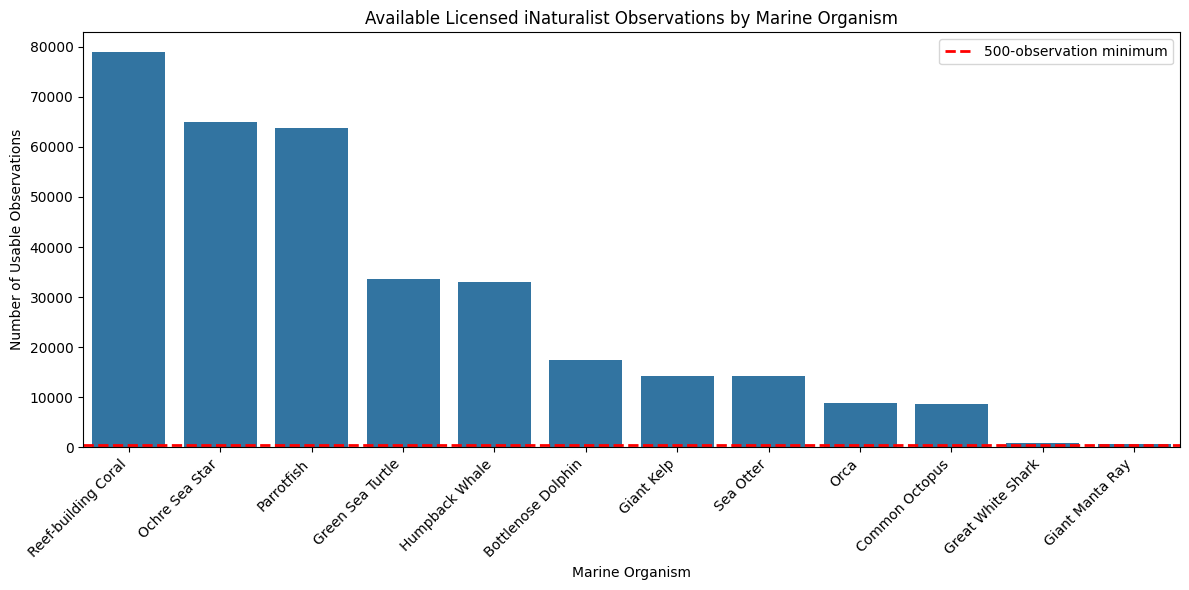

<Figure size 640x480 with 0 Axes>

In [22]:

import matplotlib.pyplot as plt
import seaborn as sns

# Sort marine organism categories from the greatest to the fewest
# available licensed observations to make comparisons easier.
availability_df = availability_df.sort_values(
    "Usable Observations", ascending=False
)

# Create a bar plot comparing the availability of licensed
# iNaturalist observations across the 12 marine organism categories.
plt.figure(figsize=(12, 6))

sns.barplot(
    data=availability_df,
    x="Category",
    y="Usable Observations"
)

# Add a horizontal reference line at 500 observations.
# This represents the minimum number of observations needed
# to support the target of 500 images per category.
plt.axhline(
    500,
    color="red",
    linestyle="--",
    linewidth=2,
    label="500-observation minimum"
)

# Add descriptive labels and format the plot for readability.
plt.title("Available Licensed iNaturalist Observations by Marine Organism")
plt.xlabel("Marine Organism")
plt.ylabel("Number of Usable Observations")

# Rotate category labels to prevent overlap.
plt.xticks(rotation=45, ha="right")

# Display the reference-line legend and adjust spacing.
plt.legend()
plt.tight_layout()

# Display the completed exploratory data analysis visualization.
plt.show()

# Save the completed exploratory data analysis visualization.
plt.savefig(
    os.path.join(OUTPUT_DIR, "observation_availability.png"),
    dpi=300,
    bbox_inches="tight"
)

# Display the completed visualization.
plt.show()


# **Prepare the train-validation-test**

In [23]:

import requests
import pandas as pd
import random
import time

# Set random seed to make the dataset shuffling and train/validation/test
# assignments reproducible.
random.seed(42)

# Define the 12 marine organism categories and their iNaturalist taxon IDs.
species = {
    "Sea Otter": 41860,
    "Humpback Whale": 41565,
    "Orca": 41521,
    "Bottlenose Dolphin": 41482,
    "Parrotfish": 516508,
    "Giant Manta Ray": 623966,
    "Great White Shark": 50873,
    "Giant Kelp": 124748,
    "Ochre Sea Star": 49699,
    "Common Octopus": 49315,
    "Reef-building Coral": 47532,
    "Green Sea Turtle": 39659
}

# Specify Creative Commons licenses that permit image reuse,
# subject to the conditions of each individual license.
allowed_licenses = [
    "cc0", "cc-by", "cc-by-nc",
    "cc-by-sa", "cc-by-nd",
    "cc-by-nc-sa", "cc-by-nc-nd"
]

# iNaturalist API endpoint and target number of observations per category.
API_URL = "https://api.inaturalist.org/v1/observations"
target = 500

# Store metadata for all categories in one master list.
all_observations = []

# Retrieve observations separately for each marine organism category.
for category, taxon_id in species.items():

    print(f"\nRetrieving observations: {category}")

    # Configure API request to retrieve research-grade observations
    # that contain photos with eligible reuse licenses.
    params = {
        "taxon_id": taxon_id,
        "photos": "true",
        "quality_grade": "research",
        "photo_license": ",".join(allowed_licenses),
        "per_page": 200,
        "page": 1,
        "order_by": "id",
        "order": "desc"
    }

    # Store eligible observations for the current category.
    category_observations = []

    # Track observation IDs to prevent duplicate entries.
    seen_ids = set()

    # Continue retrieving observations until the target is reached
    # or no additional observations are returned by the API.
    while len(category_observations) < target:

        response = requests.get(
            API_URL,
            params=params,
            timeout=60
        )

        # Check for unsuccessful API requests.
        response.raise_for_status()
        observations = response.json()["results"]

        # Stop if there are no more observations to retrieve.
        if not observations:
            break

        # Examine each observation returned by the API.
        for obs in observations:

            obs_id = obs["id"]

            # Skip observations that have already been collected.
            if obs_id in seen_ids:
                continue

            # Identify photos associated with the observation.
            photos = obs.get("photos", [])

            # Retain only photos with licenses that permit reuse.
            licensed_photos = [
                photo for photo in photos
                if photo.get("license_code") in allowed_licenses
            ]

            # Skip observations without an eligible licensed photo.
            if not licensed_photos:
                continue

            # Select the first eligible photo associated with the observation.
            photo = licensed_photos[0]

            # Store observation metadata and the selected image URL.
            # The image itself is not downloaded in this step.
            category_observations.append({
                "category": category,
                "taxon_id": taxon_id,
                "observation_id": obs_id,
                "scientific_name": obs["taxon"]["name"],
                "observation_url": obs["uri"],
                "image_url": photo["url"],
                "license": photo["license_code"],
                "photographer": obs.get("user", {}).get("login"),
                "latitude": obs.get("location", "").split(",")[0]
                    if obs.get("location") else None,
                "longitude": obs.get("location", "").split(",")[1]
                    if obs.get("location") else None
            })

            seen_ids.add(obs_id)

            # Stop collecting once the target number of observations is reached.
            if len(category_observations) >= target:
                break

        # Move to the next page of API results.
        params["page"] += 1

        # Pause between requests to avoid overwhelming the iNaturalist API.
        time.sleep(1)

    # Randomize observation order before assigning dataset splits.
    random.shuffle(category_observations)

    # Divide observations into training (70%), validation (15%),
    # and testing (15%) subsets for each category.
    n = len(category_observations)
    train_end = int(n * 0.70)
    val_end = int(n * 0.85)

    # Assign each observation to its corresponding dataset split.
    for i, obs in enumerate(category_observations):
        if i < train_end:
            obs["split"] = "train"
        elif i < val_end:
            obs["split"] = "validation"
        else:
            obs["split"] = "test"

    # Add the current category's observations to the master dataset.
    all_observations.extend(category_observations)

    print(f"{category}: {n} observations collected")

    # Pause before retrieving the next category.
    time.sleep(1)

# Combine metadata from all categories into a single DataFrame.
dataset_df = pd.DataFrame(all_observations)

# Save the complete dataset metadata, including image URLs and split assignments.
dataset_df.to_csv(
    "marine_species_master_metadata.csv",
    index=False
)

# Save separate metadata files for the training, validation, and testing sets.
for split in ["train", "validation", "test"]:
    dataset_df[dataset_df["split"] == split].to_csv(
        f"{split}_metadata.csv",
        index=False
    )

# Summarize the number of observations assigned to each split per category.
summary = pd.crosstab(
    dataset_df["category"],
    dataset_df["split"]
)

print("\nFINAL DATASET SUMMARY")
display(summary)

# Display the total number of observations collected across all categories.
print("\nTotal observations:", len(dataset_df))





Retrieving observations: Sea Otter
Sea Otter: 500 observations collected

Retrieving observations: Humpback Whale
Humpback Whale: 500 observations collected

Retrieving observations: Orca
Orca: 500 observations collected

Retrieving observations: Bottlenose Dolphin
Bottlenose Dolphin: 500 observations collected

Retrieving observations: Parrotfish
Parrotfish: 500 observations collected

Retrieving observations: Giant Manta Ray
Giant Manta Ray: 500 observations collected

Retrieving observations: Great White Shark
Great White Shark: 500 observations collected

Retrieving observations: Giant Kelp
Giant Kelp: 500 observations collected

Retrieving observations: Ochre Sea Star
Ochre Sea Star: 500 observations collected

Retrieving observations: Common Octopus
Common Octopus: 500 observations collected

Retrieving observations: Reef-building Coral
Reef-building Coral: 500 observations collected

Retrieving observations: Green Sea Turtle
Green Sea Turtle: 500 observations collected

FINAL D

split,test,train,validation
category,,,
Bottlenose Dolphin,75,350,75
Common Octopus,75,350,75
Giant Kelp,75,350,75
Giant Manta Ray,75,350,75
Great White Shark,75,350,75
Green Sea Turtle,75,350,75
Humpback Whale,75,350,75
Ochre Sea Star,75,350,75
Orca,75,350,75



Total observations: 6000


# **Mount google drive**

# **Create dataset folders**

In [25]:
import os

# Define the main directory where the marine classification dataset
# will be stored in Google Drive.
BASE_DIR = "/content/drive/MyDrive/Marine_Classification"

# Create separate directories for the training, validation, and test sets.
# Within each split, create one folder for each of the 12 organism categories.
# exist_ok=True prevents errors if the directories already exist.
for split in ["train", "validation", "test"]:
    for category in species.keys():
        folder = os.path.join(BASE_DIR, split, category)
        os.makedirs(folder, exist_ok=True)

print("Dataset folders created!")



Dataset folders created!


# Download the **images**

In [26]:

import pandas as pd
import requests
from PIL import Image
from io import BytesIO
import os
import time

# Load the master metadata CSV containing image URLs, observation IDs,
# category labels, and train/validation/test assignments.
df = pd.read_csv("marine_species_master_metadata.csv")

# Create a persistent HTTP session to reuse connections during image downloads.
session = requests.Session()

# Track the number of successfully downloaded images and any failed downloads.
successful = 0
failed = []

# Iterate through the metadata to download each image.
for index, row in df.iterrows():

    # Extract the image's category, dataset split, observation ID, and URL.
    category = row["category"]
    split = row["split"]
    obs_id = row["observation_id"]
    image_url = row["image_url"]

    # Determine the destination folder based on the assigned dataset split
    # and organism category.
    folder = os.path.join(BASE_DIR, split, category)
    image_path = os.path.join(folder, f"{obs_id}.jpg")

    # Skip images that have already been downloaded to avoid duplicates
    # when rerunning the notebook.
    if os.path.exists(image_path):
        successful += 1
        continue

    try:
        # Replace the square thumbnail URL with the medium-resolution version
        # to obtain a larger image for model training.
        medium_url = image_url.replace("square", "medium")

        # Send an HTTP request to retrieve the image.
        response = session.get(medium_url, timeout=30)
        response.raise_for_status()

        # Load the downloaded image from its response content.
        img = Image.open(BytesIO(response.content))

        # Convert images to RGB so all images have a consistent three-channel
        # color format compatible with the image-loading pipeline.
        img = img.convert("RGB")

        # Save the processed image as a JPEG in its assigned dataset folder.
        img.save(image_path, "JPEG", quality=95)

        successful += 1

    except Exception as e:
        # Record unsuccessful downloads so they can be reviewed or retried.
        failed.append({
            "observation_id": obs_id,
            "category": category,
            "url": image_url,
            "error": str(e)
        })

    # Print progress after every 100 images.
    if (index + 1) % 100 == 0:
        print(f"Processed {index + 1}/{len(df)} images")

# Report the final download statistics.
print("\nDOWNLOAD COMPLETE")
print("Successful:", successful)
print("Failed:", len(failed))

# Save information about failed downloads to a CSV file for troubleshooting.
pd.DataFrame(failed).to_csv(
    os.path.join(BASE_DIR, "failed_downloads.csv"),
    index=False
)


Processed 100/6000 images
Processed 200/6000 images
Processed 300/6000 images
Processed 400/6000 images
Processed 500/6000 images
Processed 600/6000 images
Processed 700/6000 images
Processed 800/6000 images
Processed 900/6000 images
Processed 1000/6000 images
Processed 1100/6000 images
Processed 1200/6000 images
Processed 1300/6000 images
Processed 1400/6000 images
Processed 1500/6000 images
Processed 1600/6000 images
Processed 1700/6000 images
Processed 1800/6000 images
Processed 1900/6000 images
Processed 2000/6000 images
Processed 2100/6000 images
Processed 2200/6000 images
Processed 2300/6000 images
Processed 2400/6000 images
Processed 2500/6000 images
Processed 2600/6000 images
Processed 2700/6000 images
Processed 2800/6000 images
Processed 2900/6000 images
Processed 3000/6000 images
Processed 3100/6000 images
Processed 3200/6000 images
Processed 3300/6000 images
Processed 3400/6000 images
Processed 3500/6000 images
Processed 3600/6000 images
Processed 3700/6000 images
Processed 

# **Check if downloaded images can be opened**

In [27]:

import os
from PIL import Image
import pandas as pd

# Define the directory containing the downloaded marine organism dataset.
BASE_DIR = "/content/drive/MyDrive/Marine_Classification"

# Store image integrity results for each category and dataset split.
quality_results = []

# Check image integrity separately for the training, validation, and test sets.
for split in ["train", "validation", "test"]:
    for category in species.keys():

        # Identify the folder containing images for the current category and split.
        folder = os.path.join(BASE_DIR, split, category)

        # Retrieve all JPEG image filenames in the folder.
        files = [
            f for f in os.listdir(folder)
            if f.lower().endswith(".jpg")
        ]

        # Initialize counters for valid and corrupted images.
        valid = 0
        corrupted = 0

        # Attempt to verify each downloaded image.
        for file in files:
            path = os.path.join(folder, file)

            try:
                # Verify that the image file is readable and not corrupted.
                with Image.open(path) as img:
                    img.verify()
                valid += 1

            # Count files that cannot be opened or verified as valid images.
            except Exception:
                corrupted += 1

        # Record image integrity statistics for the current category and split.
        quality_results.append({
            "Split": split,
            "Category": category,
            "Downloaded": len(files),
            "Valid": valid,
            "Corrupted": corrupted
        })

# Combine image integrity results into a summary DataFrame.
quality_df = pd.DataFrame(quality_results)

# Display the number of downloaded, valid, and corrupted images
# for every organism category and dataset split.
display(quality_df)

# Report overall image integrity statistics across the complete dataset.
print("Total downloaded:", quality_df["Downloaded"].sum())
print("Total valid:", quality_df["Valid"].sum())
print("Total corrupted:", quality_df["Corrupted"].sum())


,Split,Category,Downloaded,Valid,Corrupted
0,train,Sea Otter,350,350,0
1,train,Humpback Whale,350,350,0
2,train,Orca,350,350,0
3,train,Bottlenose Dolphin,350,350,0
4,train,Parrotfish,350,350,0
5,train,Giant Manta Ray,350,350,0
6,train,Great White Shark,350,350,0
7,train,Giant Kelp,350,350,0
8,train,Ochre Sea Star,350,350,0
9,train,Common Octopus,350,350,0


Total downloaded: 6000
Total valid: 6000
Total corrupted: 0


#EDA plot: shows an image for each organism to validate pulled correct images

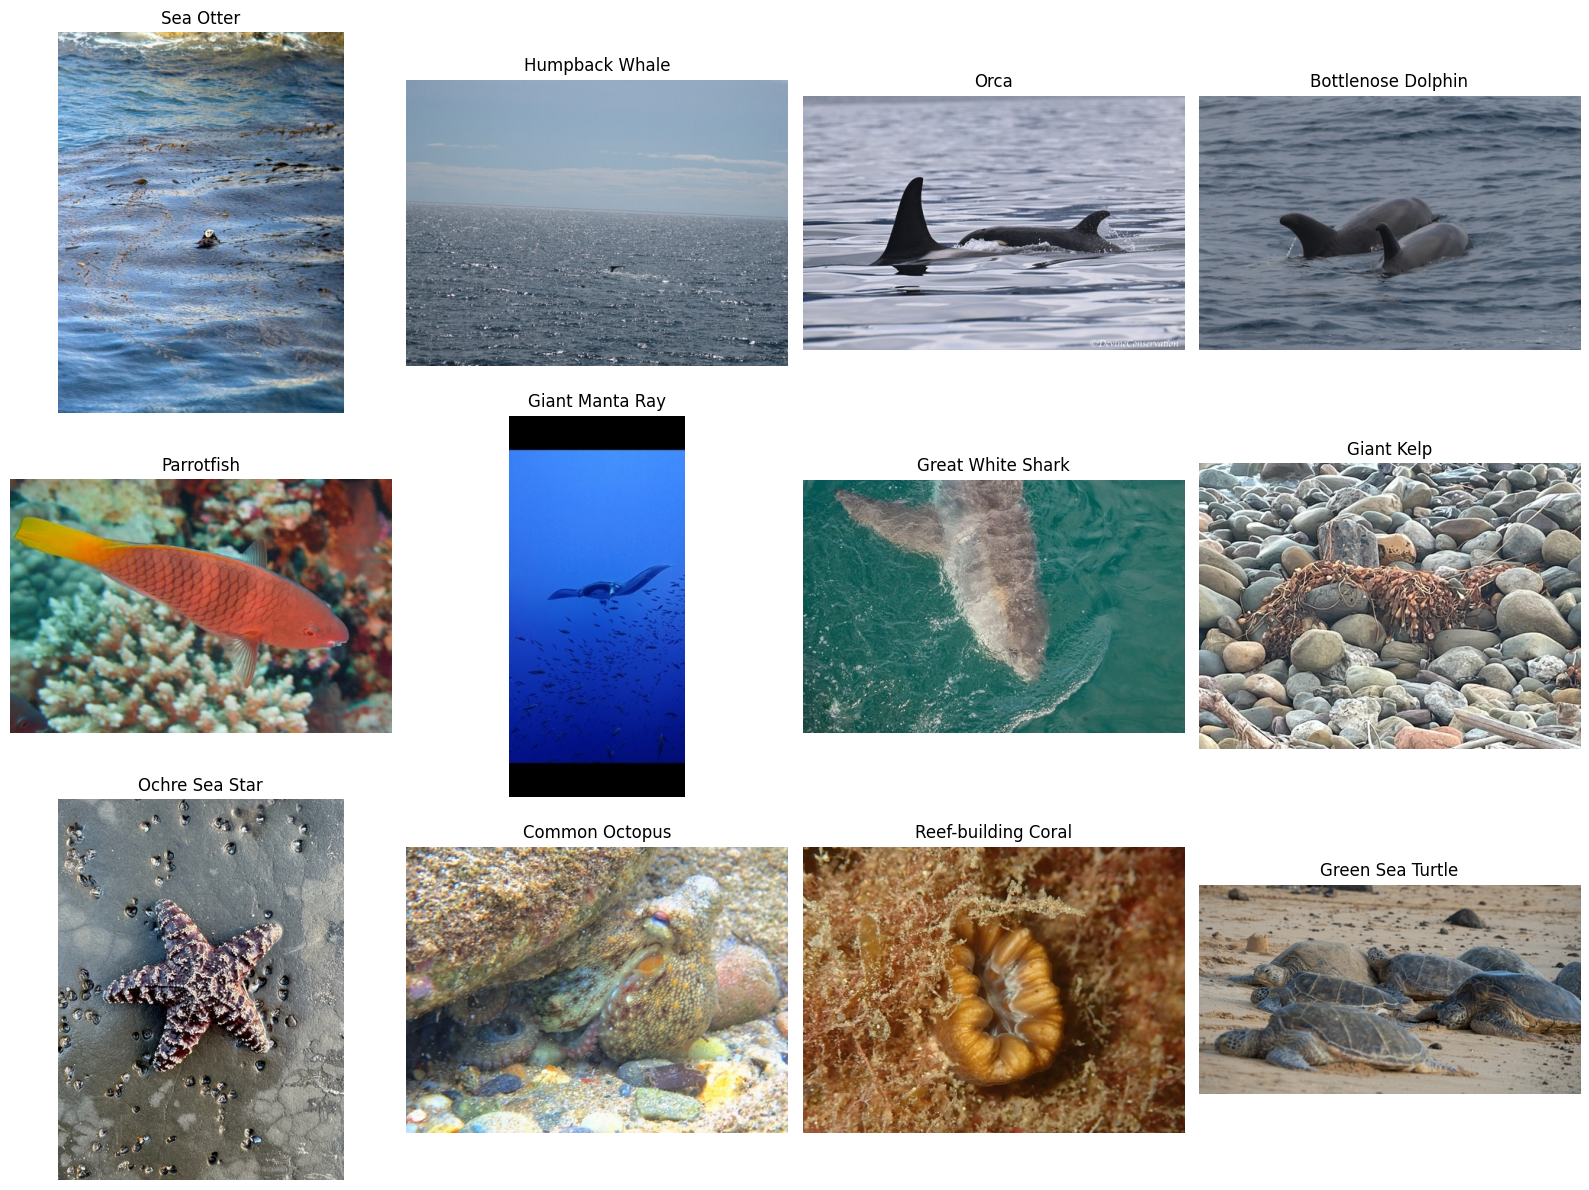

In [28]:

import matplotlib.pyplot as plt
import random
from PIL import Image
import os

# Retrieve the 12 marine organism categories.
categories = list(species.keys())

# Create a 3-by-4 grid to display one example image per category.
fig, axes = plt.subplots(3, 4, figsize=(16, 12))

# Select and display one randomly chosen training image from each category.
for ax, category in zip(axes.flatten(), categories):

    # Locate the folder containing training images for the current category.
    folder = os.path.join(BASE_DIR, "train", category)

    # Retrieve all JPEG image filenames in the category folder.
    files = [
        f for f in os.listdir(folder)
        if f.lower().endswith(".jpg")
    ]

    # Randomly select one image to visually inspect.
    filename = random.choice(files)
    img = Image.open(os.path.join(folder, filename))

    # Display the image with its corresponding organism category.
    ax.imshow(img)
    ax.set_title(category)
    ax.axis("off")

# Adjust spacing between images and display the completed visualization.
plt.tight_layout()
plt.show()


# **EDA on Image Size**

Total images analyzed: 6000

Aspect Ratio Summary:
count    6000.000000
mean        1.281036
std         0.383300
min         0.344000
25%         1.000000
50%         1.333333
75%         1.501502
max         3.571429
Name: Aspect_Ratio, dtype: float64


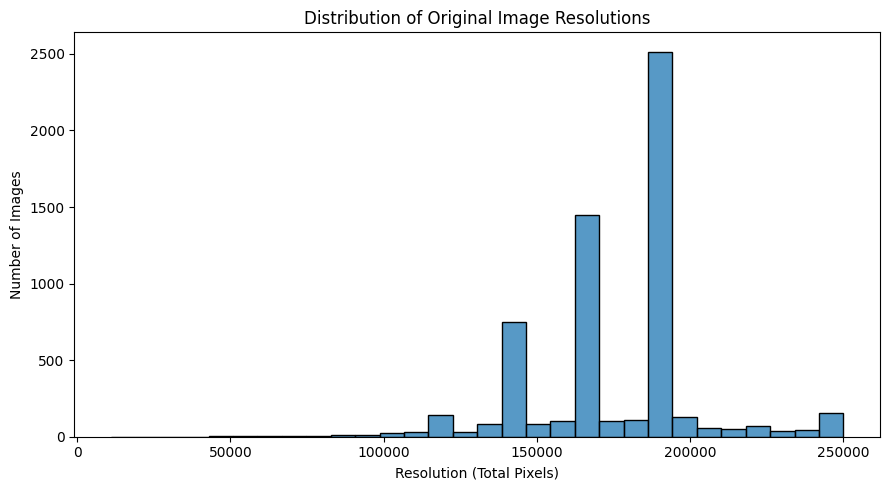

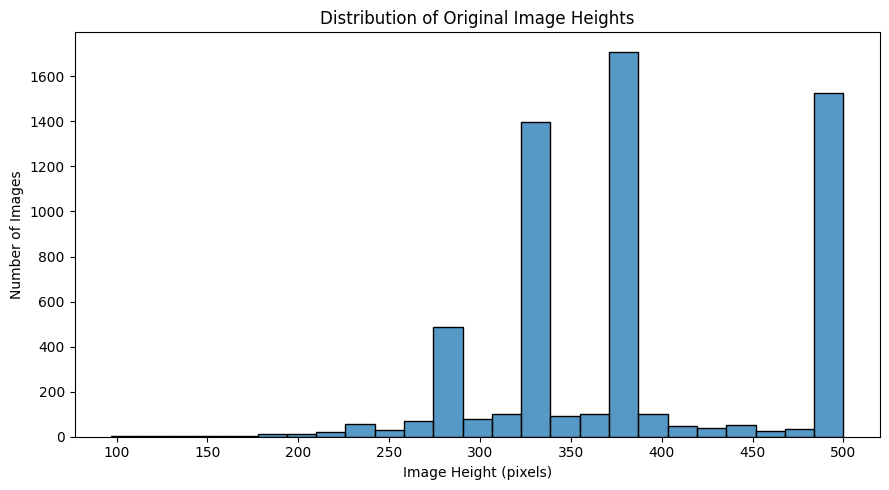

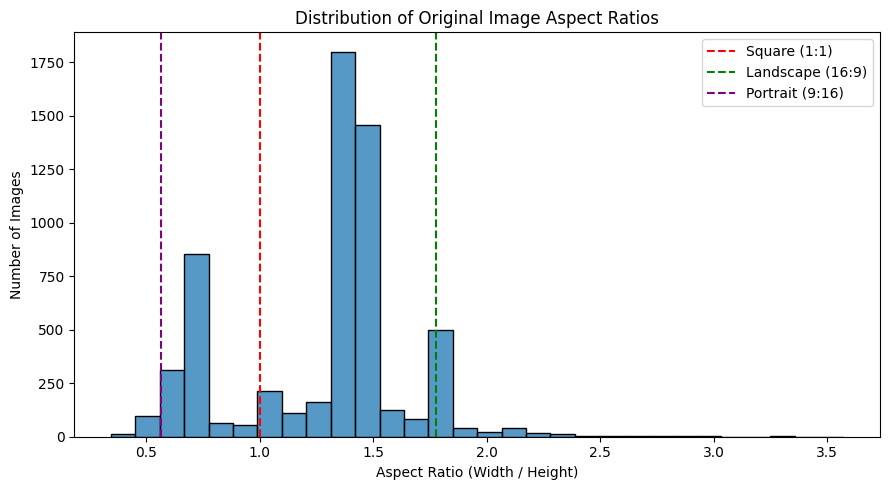


Image Dimension Summary by Dataset Split:
             Width         Height        Resolution           Aspect_Ratio  \
              mean median    mean median       mean    median         mean   
Split                                                                        
test        464.69  500.0  383.61  375.0  174442.90  187500.0         1.29   
train       462.68  500.0  384.90  375.0  174160.36  187500.0         1.28   
validation  467.48  500.0  382.53  375.0  175189.41  187500.0         1.29   

                   
           median  
Split              
test         1.33  
train        1.33  
validation   1.33  

EDA plots saved to: /content/drive/MyDrive/Marine_Classification/EDA_Results


In [31]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Define the dataset splits and image formats to include in the analysis.
splits = ["train", "validation", "test"]
image_extensions = (".jpg", ".jpeg", ".png")

# Create a list to store image dimensions and associated metadata.
image_data = []

# Loop through each dataset split and organism category to examine image files.
for split in splits:
    split_dir = os.path.join(BASE_DIR, split)

    for species in os.listdir(split_dir):
        species_dir = os.path.join(split_dir, species)

        # Skip entries that are not category directories.
        if not os.path.isdir(species_dir):
            continue

        for filename in os.listdir(species_dir):
            if filename.lower().endswith(image_extensions):
                filepath = os.path.join(species_dir, filename)

                try:
                    # Open each image and extract its original dimensions.
                    with Image.open(filepath) as img:
                        width, height = img.size

                        # Store image dimensions, resolution, and dataset information.
                        image_data.append({
                            "Category": species,
                            "Split": split,
                            "Filename": filename,
                            "Width": width,
                            "Height": height,
                            "Resolution": width * height
                        })

                except Exception:
                    # Skip images that cannot be opened or read.
                    pass

# Convert the collected image information into a DataFrame.
resolution_df = pd.DataFrame(image_data)

# Calculate each image's original width-to-height ratio.
resolution_df["Aspect_Ratio"] = (
    resolution_df["Width"] / resolution_df["Height"]
)

# Create a folder in Google Drive for saving EDA visualizations.
EDA_DIR = os.path.join(BASE_DIR, "EDA_Results")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Display the total number of images analyzed and summarize their aspect ratios.
print("Total images analyzed:", len(resolution_df))
print("\nAspect Ratio Summary:")
print(resolution_df["Aspect_Ratio"].describe())


# Plot 1: Distribution of original image resolutions.
# Resolution represents the total number of pixels (width × height).
plt.figure(figsize=(9, 5))

sns.histplot(data=resolution_df, x="Resolution", bins=30)

plt.title("Distribution of Original Image Resolutions")
plt.xlabel("Resolution (Total Pixels)")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "original_image_resolutions.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# Plot 2: Distribution of original image heights.
# This examines variation in the vertical dimensions of downloaded images.
plt.figure(figsize=(9, 5))

sns.histplot(data=resolution_df, x="Height", bins=25)

plt.title("Distribution of Original Image Heights")
plt.xlabel("Image Height (pixels)")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "original_image_heights.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# Plot 3: Distribution of original image aspect ratios.
# This examines variation in image shape before resizing images to 224 × 224.
plt.figure(figsize=(9, 5))

sns.histplot(data=resolution_df, x="Aspect_Ratio", bins=30)

# Add reference lines for common aspect ratios.
plt.axvline(1.0, color="red", linestyle="--", label="Square (1:1)")
plt.axvline(16/9, color="green", linestyle="--", label="Landscape (16:9)")
plt.axvline(9/16, color="purple", linestyle="--", label="Portrait (9:16)")

plt.title("Distribution of Original Image Aspect Ratios")
plt.xlabel("Aspect Ratio (Width / Height)")
plt.ylabel("Number of Images")
plt.legend()

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "original_image_aspect_ratios.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# Compare original image dimensions across training, validation,
# and test splits to identify potential differences in image properties.
split_summary = resolution_df.groupby("Split").agg({
    "Width": ["mean", "median"],
    "Height": ["mean", "median"],
    "Resolution": ["mean", "median"],
    "Aspect_Ratio": ["mean", "median"]
})

print("\nImage Dimension Summary by Dataset Split:")
print(split_summary.round(2))

print(f"\nEDA plots saved to: {EDA_DIR}")



# **Load and Prepare Image Datasets for Model Training**

In [32]:

import tensorflow as tf
import os

# Define the directory containing the organized marine organism dataset.
BASE_DIR = "/content/drive/MyDrive/Marine_Classification"

# Set image dimensions, batch size, and random seed for reproducibility.
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# Load the training images from their category-specific folders.
# Images are resized to 224 x 224 pixels and assigned integer labels.
# Shuffle the data to vary the order in which images are presented during training.
train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_DIR, "train"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

# Retrieve the class names and their corresponding label ordering
# established by the training dataset.
class_names = train_ds.class_names

# Load the validation dataset using the same class ordering as the training set.
# Shuffling is disabled to maintain a consistent image order during evaluation.
val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_DIR, "validation"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=class_names,
    shuffle=False
)

# Load the independent test dataset using the same class ordering.
# These images are held out from model training and validation.
test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_DIR, "test"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=class_names,
    shuffle=False
)

# Enable automatic performance optimization for the input pipelines.
AUTOTUNE = tf.data.AUTOTUNE

# Prefetch batches so that images can be prepared while the model
# processes the current batch, reducing input-loading delays.
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

# Display the category names and confirm the total number of classes.
print("Classes:", class_names)
print("Number of classes:", len(class_names))


Found 4200 files belonging to 12 classes.
Found 900 files belonging to 12 classes.
Found 900 files belonging to 12 classes.
Classes: ['Bottlenose Dolphin', 'Common Octopus', 'Giant Kelp', 'Giant Manta Ray', 'Great White Shark', 'Green Sea Turtle', 'Humpback Whale', 'Ochre Sea Star', 'Orca', 'Parrotfish', 'Reef-building Coral', 'Sea Otter']
Number of classes: 12


# **MobileNetV2 Transfer Learning Model Architecture**

In [33]:

import tensorflow as tf
from tensorflow.keras import layers, models

# Determine the number of organism categories for the classification output.
num_classes = len(class_names)

# Load MobileNetV2 using weights pretrained on the ImageNet dataset.
# Exclude the original classification layer so the network can be used
# as a feature extractor for the marine organism classification task.
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pretrained MobileNetV2 layers so their weights remain unchanged
# during initial training. Only the newly added classification layers are trained.
base_model.trainable = False

# Define the input layer for 224 x 224 RGB images.
inputs = layers.Input(shape=(224, 224, 3))

# Apply the preprocessing function required for MobileNetV2.
# This scales pixel values to the range expected by the pretrained network.
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)

# Extract image features using the frozen pretrained MobileNetV2 backbone.
x = base_model(x, training=False)

# Add a classification head to predict the marine organism category.
# Global average pooling reduces the spatial feature maps to a feature vector.
x = layers.GlobalAveragePooling2D()(x)

# Apply dropout to reduce overfitting by randomly deactivating 20% of features
# during training.
x = layers.Dropout(0.2)(x)

# Generate a probability for each organism category using softmax activation.
outputs = layers.Dense(num_classes, activation="softmax")(x)

# Combine the input, feature extraction backbone, and classification head.
mobilenet_model = models.Model(inputs, outputs)

# Configure the model for training.
mobilenet_model.compile(
    # Adam optimizer updates the trainable classification-layer weights.
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),

    # Sparse categorical crossentropy is appropriate because labels
    # are represented as integer class indices rather than one-hot vectors.
    loss="sparse_categorical_crossentropy",

    # Track classification accuracy during training and validation.
    metrics=["accuracy"]
)

# Display the model architecture, including layer output shapes and parameters.
mobilenet_model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 12)             │        15,372 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,273,356 (8.67 MB)

 Trainable params: 15,372 (60.05 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

# **Train MobileNetV2 Model**

In [34]:

# Define the number of complete passes through the training dataset.
EPOCHS = 10

# Train the MobileNetV2 model using the training dataset.
# Evaluate performance on the validation dataset after each epoch.
# Store training history, including loss and accuracy, for later analysis.
history_mobilenet = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)


Epoch 1/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 308s 2s/step - accuracy: 0.6402 - loss: 1.1157 - val_accuracy: 0.7511 - val_loss: 0.7306
Epoch 2/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 247s 2s/step - accuracy: 0.7979 - loss: 0.6062 - val_accuracy: 0.7789 - val_loss: 0.6489
Epoch 3/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 239s 2s/step - accuracy: 0.8200 - loss: 0.5134 - val_accuracy: 0.7878 - val_loss: 0.6185
Epoch 4/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 208s 2s/step - accuracy: 0.8507 - loss: 0.4416 - val_accuracy: 0.8044 - val_loss: 0.5790
Epoch 5/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 207s 2s/step - accuracy: 0.8657 - loss: 0.3840 - val_accuracy: 0.8100 - val_loss: 0.5860
Epoch 6/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 264s 2s/step - accuracy: 0.8798 - loss: 0.3613 - val_accuracy: 0.8144 - val_loss: 0.5847
Epoch 7/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 205s 2s/step - accuracy: 0.8955 - loss: 0.3239 - val_accuracy: 0.8167 - val_loss: 0.5736
Epoch 8/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 207s 2s/step - accuracy: 0.8986 - loss: 0.2986 - val_accu

# **Evaluate Model Performance**

In [35]:

# Evaluate the trained MobileNetV2 model on the independent test dataset.
# The test dataset was not used during model training or validation.
test_loss, test_accuracy = mobilenet_model.evaluate(test_ds)

# Display the final test performance metrics.
print("Test accuracy:", test_accuracy)
print("Test loss:", test_loss)


29/29 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step - accuracy: 0.8300 - loss: 0.5289
Test accuracy: 0.8299999833106995
Test loss: 0.5289461016654968


# **Evaluate Classification Performance and Analyze Misclassified Images**

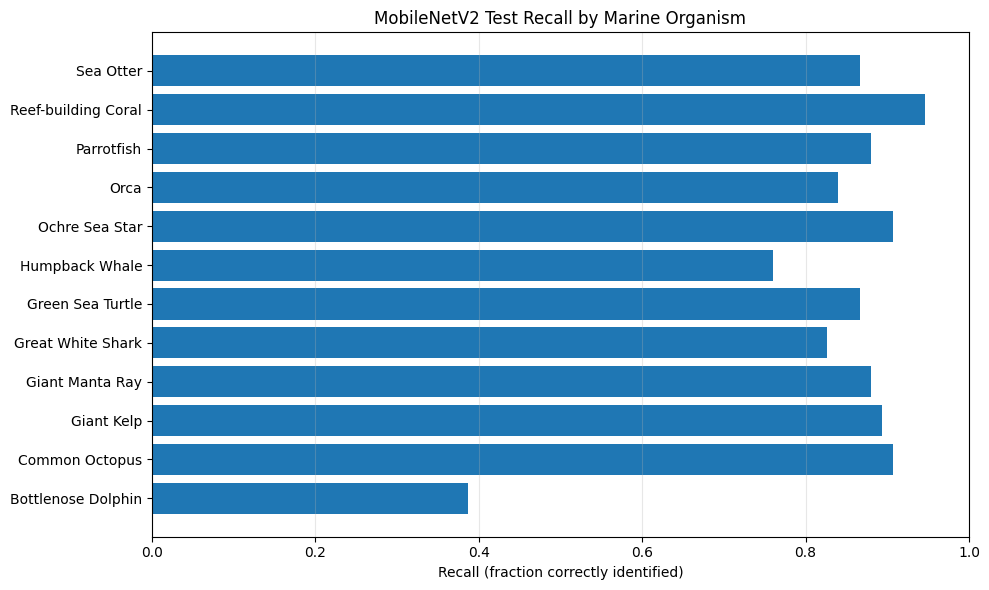

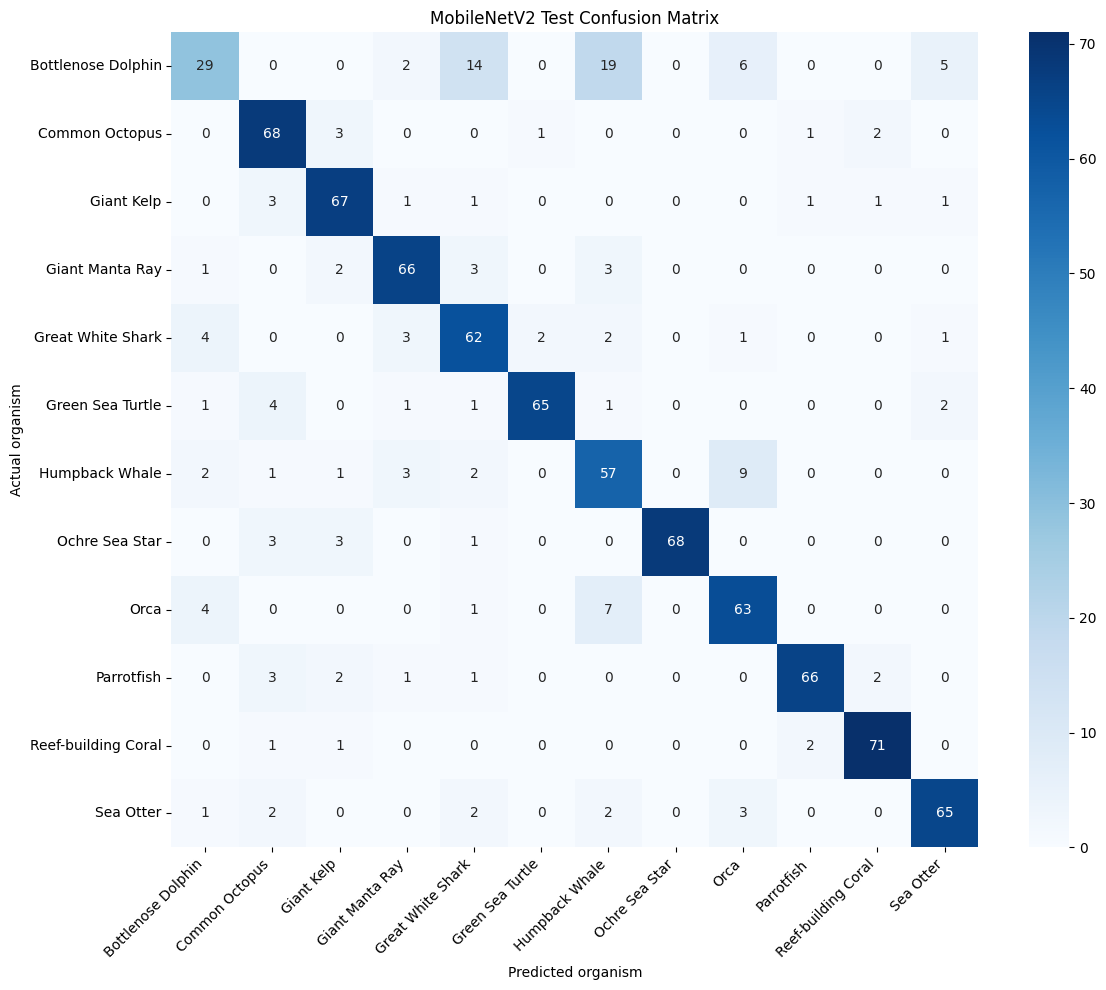

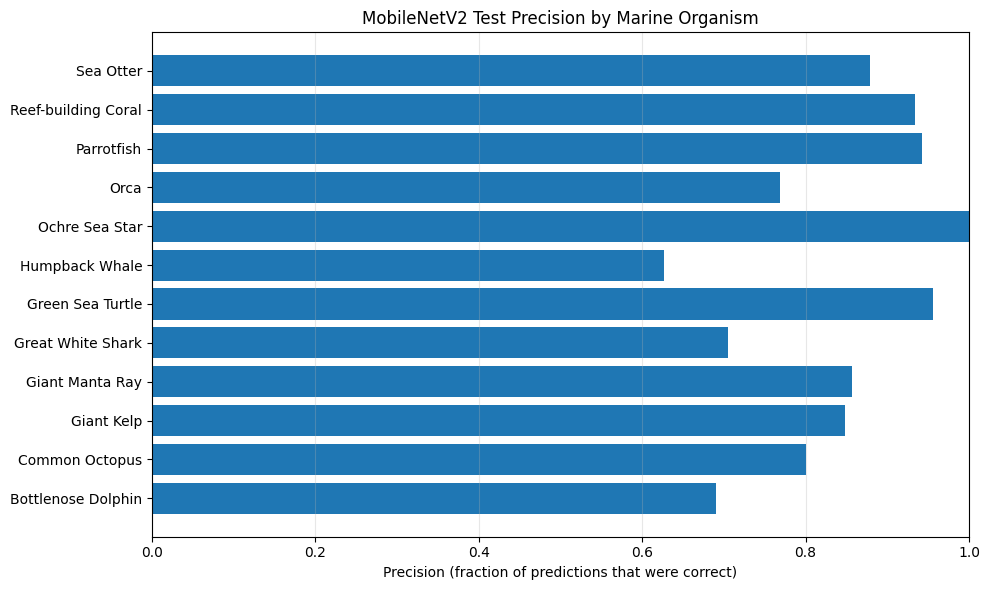

                     precision    recall  f1-score   support

 Bottlenose Dolphin       0.69      0.39      0.50        75
     Common Octopus       0.80      0.91      0.85        75
         Giant Kelp       0.85      0.89      0.87        75
    Giant Manta Ray       0.86      0.88      0.87        75
  Great White Shark       0.70      0.83      0.76        75
   Green Sea Turtle       0.96      0.87      0.91        75
     Humpback Whale       0.63      0.76      0.69        75
     Ochre Sea Star       1.00      0.91      0.95        75
               Orca       0.77      0.84      0.80        75
         Parrotfish       0.94      0.88      0.91        75
Reef-building Coral       0.93      0.95      0.94        75
          Sea Otter       0.88      0.87      0.87        75

           accuracy                           0.83       900
          macro avg       0.83      0.83      0.83       900
       weighted avg       0.83      0.83      0.83       900



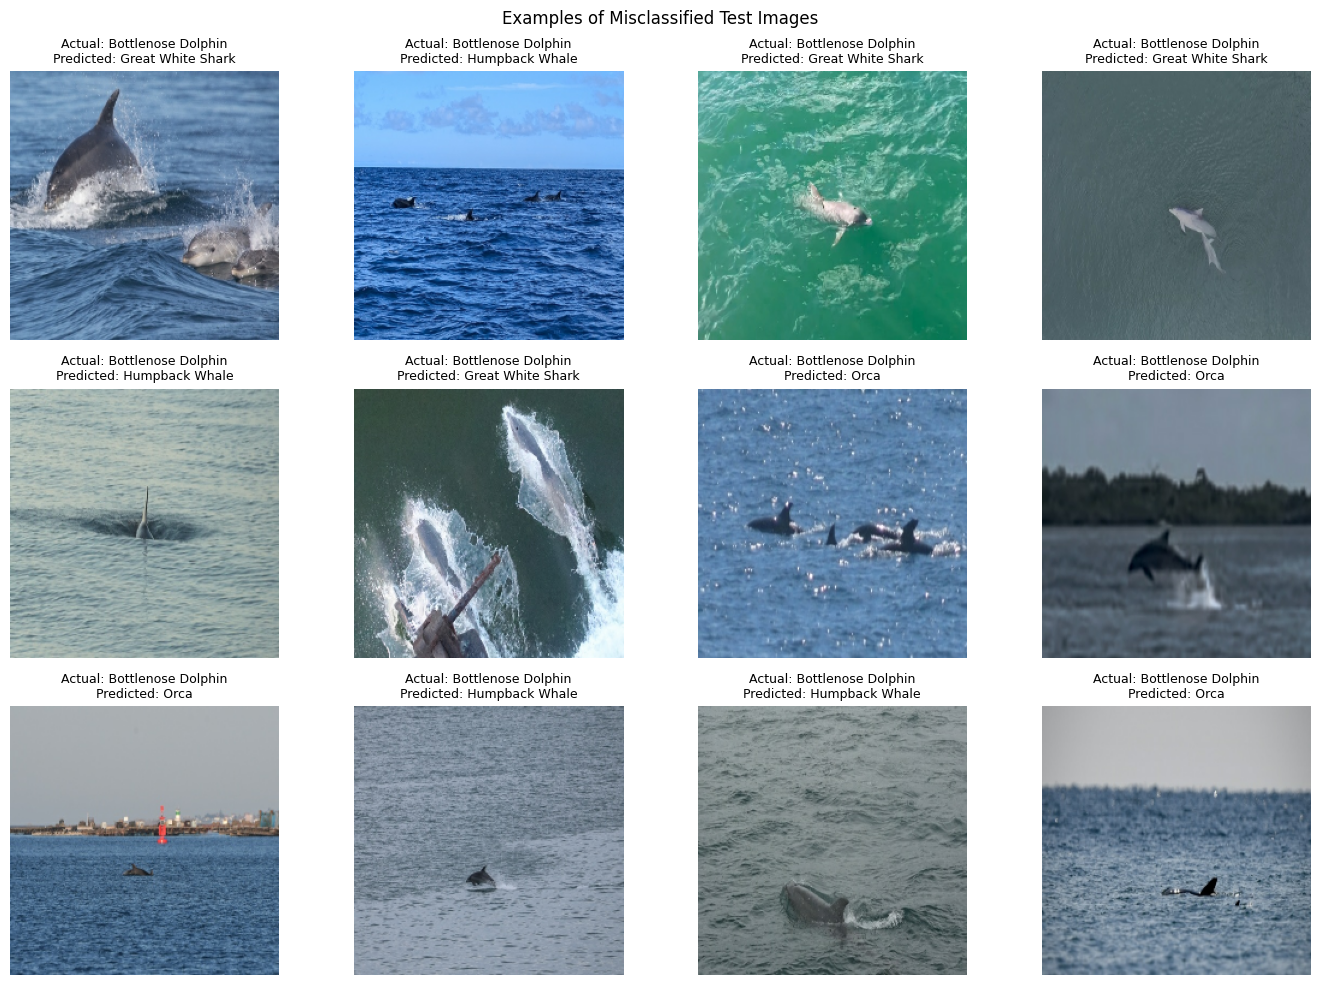

Evaluation plots saved to: /content/gdrive/MyDrive/Marine_Classification/MobileNetV2/Figures


In [37]:

import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Create a folder in Google Drive to save evaluation plots.


# Initialize lists to store actual labels, predicted labels,
# and examples of incorrectly classified test images.
y_true = []
y_pred = []
misclassified_images = []
misclassified_actual = []
misclassified_predicted = []

# Generate predictions for each batch of images in the test dataset.
for images, labels in test_ds:

    # Obtain predicted class probabilities for each test image.
    predictions = mobilenet_model.predict(images, verbose=0)

    # Convert predicted probabilities into class labels by selecting
    # the category with the highest predicted probability.
    predicted_labels = np.argmax(predictions, axis=1)
    actual_labels = labels.numpy()

    # Store actual and predicted labels for overall performance analysis.
    y_true.extend(actual_labels)
    y_pred.extend(predicted_labels)

    # Identify images for which the predicted category differs
    # from the actual category.
    wrong_indices = np.where(predicted_labels != actual_labels)[0]

    # Store up to 12 misclassified images for visual inspection.
    for idx in wrong_indices:
        if len(misclassified_images) < 12:
            misclassified_images.append(images[idx].numpy())
            misclassified_actual.append(actual_labels[idx])
            misclassified_predicted.append(predicted_labels[idx])

# Convert label lists into NumPy arrays for metric calculations.
y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Calculate per-category precision, recall, and F1-score.
# Output a dictionary so individual metrics can be used in visualizations.
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

# Plot 1: Per-category recall.
# Recall measures the proportion of actual images in each category
# that the model correctly identifies.
recalls = [report[name]["recall"] for name in class_names]

plt.figure(figsize=(10, 6))
plt.barh(class_names, recalls)
plt.xlabel("Recall (fraction correctly identified)")
plt.title("MobileNetV2 Test Recall by Marine Organism")
plt.xlim(0, 1)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(SAVE_DIR, "recall_by_organism.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Plot 2: Confusion matrix.
# Shows how often each actual category is classified as each predicted category.
# Correct predictions appear along the diagonal of the matrix.
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted organism")
plt.ylabel("Actual organism")
plt.title("MobileNetV2 Test Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(
    os.path.join(SAVE_DIR, "confusion_matrix_original.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Plot 3: Per-category precision.
# Precision measures the proportion of predictions assigned to each category
# that are actually correct.
precisions = [report[name]["precision"] for name in class_names]

plt.figure(figsize=(10, 6))
plt.barh(class_names, precisions)
plt.xlabel("Precision (fraction of predictions that were correct)")
plt.title("MobileNetV2 Test Precision by Marine Organism")
plt.xlim(0, 1)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(SAVE_DIR, "precision_by_organism.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Display a detailed classification report containing precision,
# recall, F1-score, and the number of test images (support) per category.
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

# Plot 4: Visualize up to 12 incorrectly classified test images
# to identify potential patterns in model misclassification.
n = len(misclassified_images)

if n > 0:
    fig, axes = plt.subplots(3, 4, figsize=(14, 10))
    axes = axes.flatten()

    for i, ax in enumerate(axes):
        if i < n:
            # Display the misclassified image with its actual and predicted labels.
            ax.imshow(misclassified_images[i].astype("uint8"))
            actual = class_names[misclassified_actual[i]]
            predicted = class_names[misclassified_predicted[i]]

            ax.set_title(
                f"Actual: {actual}\nPredicted: {predicted}",
                fontsize=9
            )
        ax.axis("off")

    plt.suptitle("Examples of Misclassified Test Images")
    plt.tight_layout()
    plt.savefig(
        os.path.join(OUTPUT_DIR, "misclassified_images.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
else:
    # Report when all test images were classified correctly.
    print("No misclassified images!")

print(f"Evaluation plots saved to: {OUTPUT_DIR}")




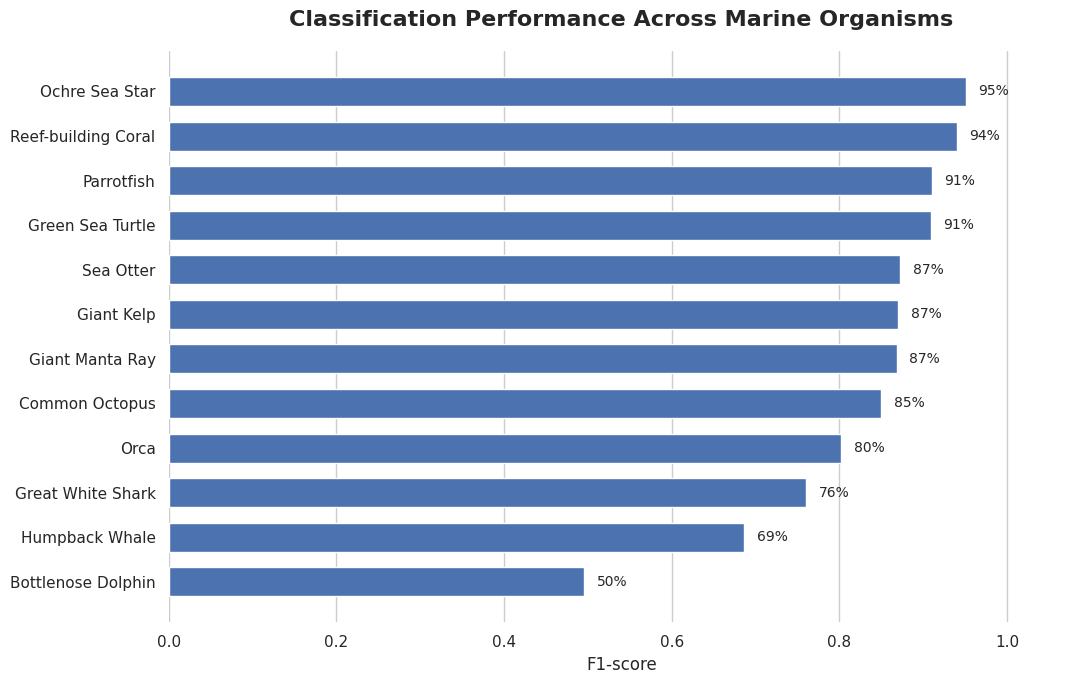

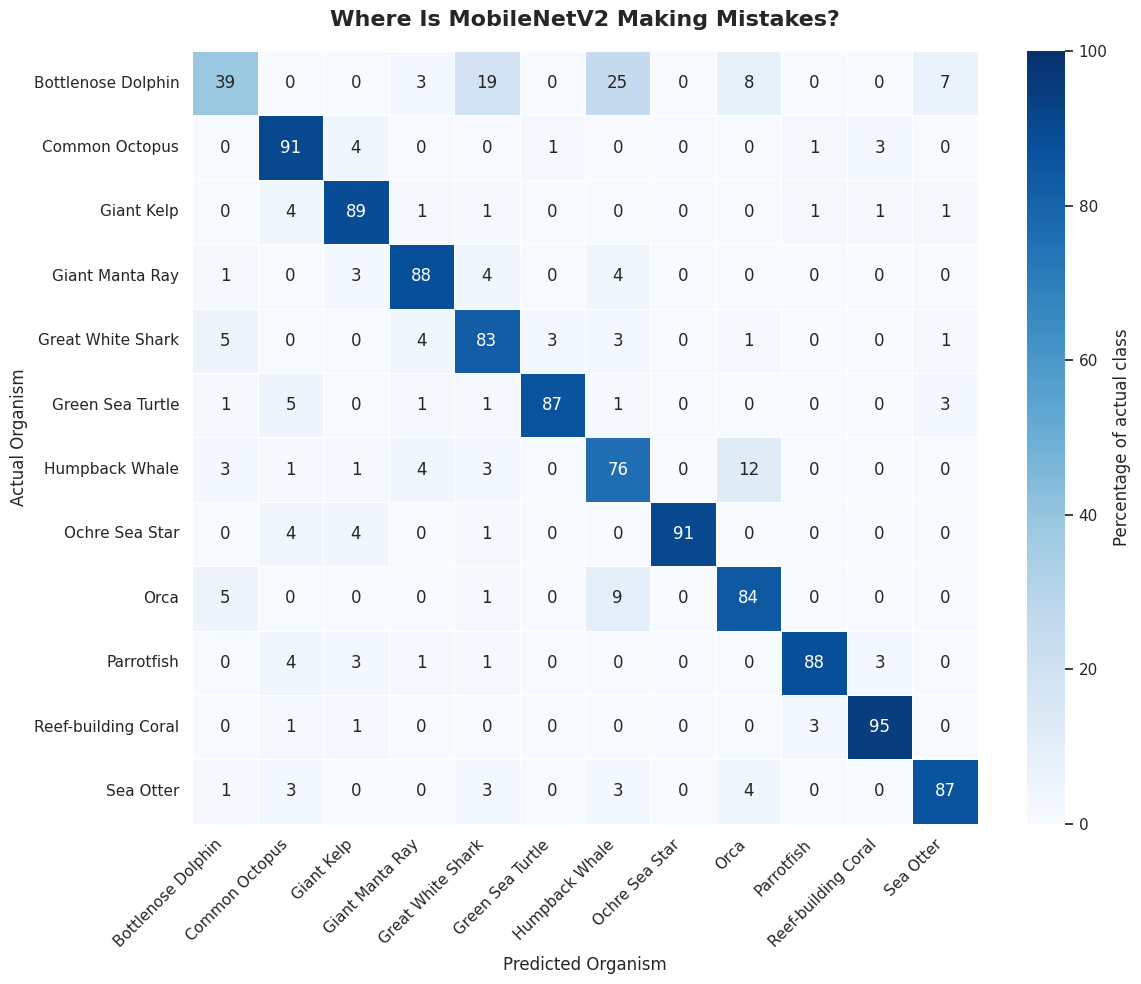

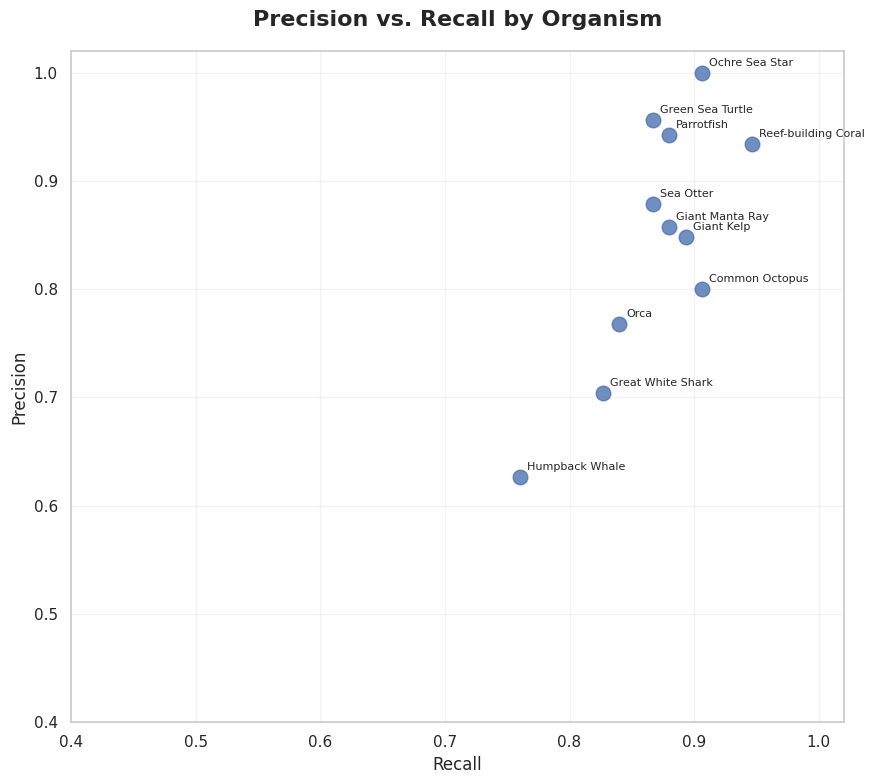

In [39]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Consistent, clean graph styling
sns.set_theme(style="whitegrid", font_scale=1.0)

# 1. F1 SCORE BY ORGANISM
# F1-score balances precision and recall for each organism.
f1_scores = [report[name]["f1-score"] for name in class_names]

fig, ax = plt.subplots(figsize=(11, 7))

# Sort organisms from lowest to highest F1-score.
sorted_indices = np.argsort(f1_scores)
sorted_names = [class_names[i] for i in sorted_indices]
sorted_scores = [f1_scores[i] for i in sorted_indices]

bars = ax.barh(sorted_names, sorted_scores, height=0.65)

# Add percentage labels to each bar.
for bar, score in zip(bars, sorted_scores):
    ax.text(score + 0.015, bar.get_y() + bar.get_height()/2,
            f"{score:.0%}", va="center", fontsize=10)

ax.set_xlim(0, 1.08)
ax.set_xlabel("F1-score", fontsize=12)
ax.set_title("Classification Performance Across Marine Organisms",
             fontsize=16, weight="bold", pad=18)
ax.set_ylabel("")
ax.grid(axis="y", visible=False)
sns.despine(left=True, bottom=True)
plt.tight_layout()

# Save F1-score visualization to Google Drive.
plt.savefig(
    os.path.join(SAVE_DIR, "f1_score_by_organism.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 2. CONFUSION MATRIX AS PERCENTAGES
# Normalize each row so each actual class sums to 100%.
# This shows the percentage of images in each actual category
# assigned to each predicted category.
cm_percent = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

fig, ax = plt.subplots(figsize=(12, 10))

sns.heatmap(
    cm_percent,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Percentage of actual class"},
    ax=ax
)

ax.set_title("Where Is MobileNetV2 Making Mistakes?",
             fontsize=16, weight="bold", pad=18)
ax.set_xlabel("Predicted Organism", fontsize=12)
ax.set_ylabel("Actual Organism", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

# Save normalized confusion matrix to Google Drive.
plt.savefig(
    os.path.join(SAVE_DIR, "confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 3. PRECISION VS RECALL
# Compare precision and recall for each organism.
precisions = [report[name]["precision"] for name in class_names]
recalls = [report[name]["recall"] for name in class_names]

fig, ax = plt.subplots(figsize=(9, 8))

ax.scatter(recalls, precisions, s=110, alpha=0.8)

# Label each point with its corresponding organism.
for i, name in enumerate(class_names):
    ax.annotate(name, (recalls[i], precisions[i]),
                xytext=(5, 5), textcoords="offset points",
                fontsize=8)

ax.set_xlim(0.4, 1.02)
ax.set_ylim(0.4, 1.02)
ax.set_xlabel("Recall", fontsize=12)
ax.set_ylabel("Precision", fontsize=12)
ax.set_title("Precision vs. Recall by Organism",
             fontsize=16, weight="bold", pad=18)
ax.grid(alpha=0.25)
plt.tight_layout()

# Save precision-versus-recall visualization to Google Drive.
plt.savefig(
    os.path.join(OUTPUT_DIR, "precision_vs_recall.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()



# **Saved Trained MobileNetV2 Model**

In [40]:

# Define the Google Drive path for saving the trained model.
MODEL_PATH = "/content/drive/MyDrive/Marine_Classification/mobilenetv2_pretrained.keras"

# Save the trained MobileNetV2 model, including its architecture and learned weights.
mobilenet_model.save(MODEL_PATH)

print(f"Model successfully saved to: {MODEL_PATH}")


Model successfully saved to: /content/drive/MyDrive/Marine_Classification/mobilenetv2_pretrained.keras
